# AQI v2 · An Italian city (UCI Air Quality)
## Low-cost sensors as virtual reference analyzers, and hourly AQI forecasting

*Florian Grolleau · Air Quality Index Studies, version 2*

The UCI Air Quality dataset (De Vito et al., 2008) pairs, for one year of hourly data in
a polluted Italian city, five cheap metal-oxide (MOx) gas sensors with certified
reference analyzers. Version 1 (`AirQualityIndex.ipynb`) used it to fit Prophet on
relative humidity and a random forest on CO. This notebook:

1. **Audits v1**: four preprocessing and validation errors, and what they cost.
2. Computes an **hourly AQI** for the city (EPA and European CAQI) from the reference
   analyzers.
3. Turns the cheap sensors into **virtual reference analyzers**, and shows how fast they
   drift and how often they must be recalibrated.
4. Uses them to **fill the gaps** of the reference network, validated by masking.
5. **Forecasts the hourly AQI** 1 to 24 hours ahead with calibrated uncertainty.

In [1]:
import sys
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.model_selection import train_test_split

sys.path.insert(0, str(Path.cwd().parent))
from aqi2 import data, features, forecasting as fc, indices as ix, viz  # noqa: E402

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
viz.set_theme()
RNG = np.random.default_rng(7)

SENSORS = ["s1_co", "s2_nmhc", "s3_nox", "s4_no2", "s5_o3"]
METEO = ["t", "rh", "ah"]
LABELS = {"co_gt": "CO (mg/m³)", "no2_gt": "NO₂ (µg/m³)", "nox_gt": "NOx (ppb)",
          "c6h6_gt": "benzene (µg/m³)"}

## 1 · Auditing version 1

v1 read the file with `sep=";"` only. Every column written with a decimal comma (CO,
benzene, T, RH, AH) was therefore read as text, and `replace(-200, NaN)` ran *before*
that text was converted: **the missing-value code -200 survived** in those columns, so
18% of the CO "measurements" and 4% of the temperatures equal -200. In the columns that
were numeric (NO2, NOx, NMHC and the five sensors) the gaps were then filled with one
number for the whole table, the mean of the column means: **457.1**.

In [2]:
raw = pd.read_csv(data.ROOT / "AirQualityUCI.csv", sep=";").head(9357)
raw = raw.drop(columns=["Unnamed: 15", "Unnamed: 16"]).replace(to_replace=-200, value=np.nan)
for col in raw.columns:  # v1 tested dtype == "object"; text columns are "str" in pandas 3
    if col not in ["Date", "Time"] and not pd.api.types.is_numeric_dtype(raw[col]):
        raw[col] = pd.to_numeric(raw[col].astype(str).str.replace(",", "."), errors="coerce")
fill_value = raw.drop(columns=["Date", "Time"]).mean(numeric_only=True).mean()
v1 = raw.fillna(fill_value)
v1.index = pd.to_datetime(raw.Date + " " + raw.Time.str.replace(".", ":"), format="%d/%m/%Y %H:%M:%S")
print(f"v1 fill value: {fill_value:.1f}")

u = data.load_uci()
audit = pd.DataFrame({
    "v1 mean": v1[["CO(GT)", "T", "RH", "NO2(GT)"]].mean().to_numpy(),
    "v1 share of -200 or 457": [((v1[c] == -200) | (v1[c].round(1) == round(fill_value, 1))).mean()
                                for c in ["CO(GT)", "T", "RH", "NO2(GT)"]],
    "v2 mean": u[["co_gt", "t", "rh", "no2_gt"]].mean().to_numpy(),
    "v2 share missing": u[["co_gt", "t", "rh", "no2_gt"]].isna().mean().to_numpy(),
}, index=["CO (mg/m3)", "T (degC)", "RH (%)", "NO2 (ug/m3)"])
display(audit.round(3))

v1 fill value: 457.1


,v1 mean,v1 share of -200 or 457,v2 mean,v2 share missing
CO (mg/m3),-34.208,0.180,2.153,0.180
T (degC),9.778,0.039,18.318,0.039
RH (%),39.485,0.039,49.234,0.039
NO2 (ug/m3),173.462,0.175,113.091,0.175


The v1 random forest scored "MAE 22.4, R2 0.645" for CO. Most of that error is the
model learning the -200 code. Two more problems remain once the data are clean:

* a **random train/test split** on an hourly time series lets the model see the hours
  on either side of each test hour;
* the **Prophet model forecast relative humidity**, not air quality.

The table compares v1 as it was, the same model on clean data, and an honest
**chronological** split (train on the first 8 weeks, test on the next 11 months).

In [3]:
X_cols_v1 = ["PT08.S1(CO)", "NMHC(GT)", "C6H6(GT)", "PT08.S2(NMHC)", "NOx(GT)", "PT08.S3(NOx)", "NO2(GT)",
             "PT08.S4(NO2)", "PT08.S5(O3)", "T", "RH", "AH"]
Xtr, Xte, ytr, yte = train_test_split(v1[X_cols_v1], v1["CO(GT)"], test_size=0.2, random_state=42)
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(Xtr, ytr)
rows = [{"protocol": "v1 as published", **fc.regression_scores(yte, rf.predict(Xte))}]

clean_cols = SENSORS + METEO
d = u[clean_cols + ["co_gt"]].dropna()
Xtr, Xte, ytr, yte = train_test_split(d[clean_cols], d.co_gt, test_size=0.2, random_state=42)
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(Xtr, ytr)
rows.append({"protocol": "clean data, random split", **fc.regression_scores(yte, rf.predict(Xte))})
cut = d.index[0] + pd.Timedelta(weeks=8)
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(d[d.index < cut][clean_cols],
                                                                             d[d.index < cut].co_gt)
rows.append({"protocol": "clean data, chronological split",
             **fc.regression_scores(d[d.index >= cut].co_gt, rf.predict(d[d.index >= cut][clean_cols]))})
protocols = pd.DataFrame(rows).set_index("protocol")
display(protocols.round(3))

,MAE,RMSE,bias,R2,n
protocol,,,,,
v1 as published,22.495,45.899,-0.351,0.643,1872
"clean data, random split",0.260,0.395,0.005,0.920,1469
"clean data, chronological split",0.327,0.500,-0.005,0.880,6276


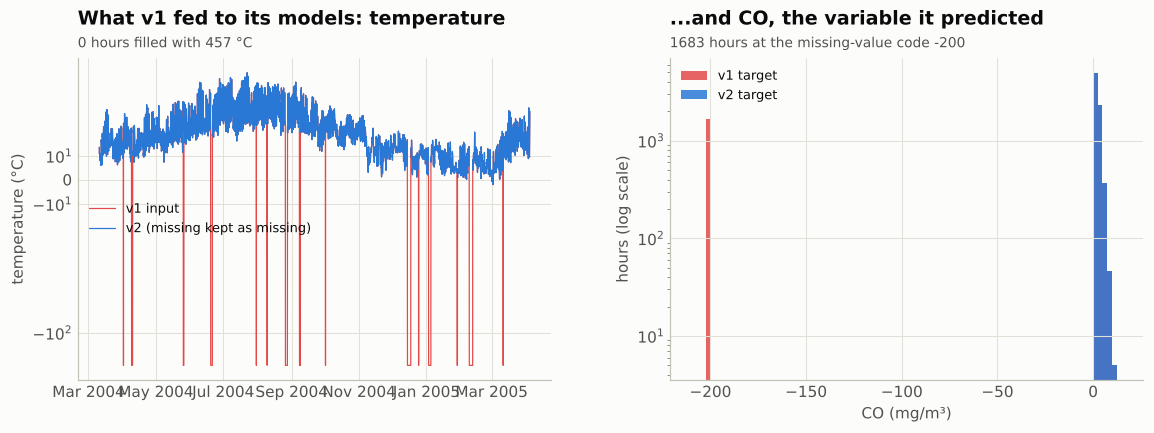

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), gridspec_kw={"wspace": 0.25})
ax = axes[0]
ax.plot(v1.index, v1["T"], color=viz.SERIES[7], lw=0.8, label="v1 input")
ax.plot(u.index, u.t, color=viz.SERIES[0], lw=0.8, label="v2 (missing kept as missing)")
ax.set_yscale("symlog", linthresh=50)
ax.set_ylabel("temperature (°C)")
viz.title(ax, "What v1 fed to its models: temperature", f"{(v1['T'].round(1) == round(fill_value, 1)).sum()} hours "
          f"filled with {fill_value:.0f} °C")
ax.legend(loc="center left", fontsize=8.5)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax = axes[1]
bins = np.linspace(-210, 15, 90)
ax.hist(v1["CO(GT)"], bins=bins, color=viz.SERIES[7], alpha=0.85, label="v1 target")
ax.hist(u.co_gt.dropna(), bins=bins, color=viz.SERIES[0], alpha=0.85, label="v2 target")
ax.set_yscale("log")
ax.set_xlabel("CO (mg/m³)")
ax.set_ylabel("hours (log scale)")
viz.title(ax, "...and CO, the variable it predicted", f"{(v1['CO(GT)'] == -200).sum()} hours at the missing-value "
          "code -200")
ax.legend(loc="upper left", fontsize=8.5)
viz.save(fig, "02_v1_audit")
plt.show()

### A second, quieter problem in the dataset itself

The reference benzene column is a deterministic function of one cheap sensor: a
4th-degree polynomial of `PT08.S2(NMHC)` reproduces it with R2 = 0.99998. The benzene
"ground truth" was therefore estimated from that sensor, not measured independently,
and any model that "predicts benzene from the sensors" is trivially perfect. Benzene is
left out of the benchmarks below.

In [5]:
bz = u[["c6h6_gt", "s2_nmhc"]].dropna()
coef = np.polyfit(bz.s2_nmhc, bz.c6h6_gt, 4)
resid = bz.c6h6_gt - np.polyval(coef, bz.s2_nmhc)
bz_r2 = 1 - resid.var() / bz.c6h6_gt.var()
print(f"benzene vs polynomial of S2: R2 = {bz_r2:.5f}, residual sd = {resid.std():.3f} ug/m3")

benzene vs polynomial of S2: R2 = 0.99998, residual sd = 0.030 ug/m3


## 2 · Data availability

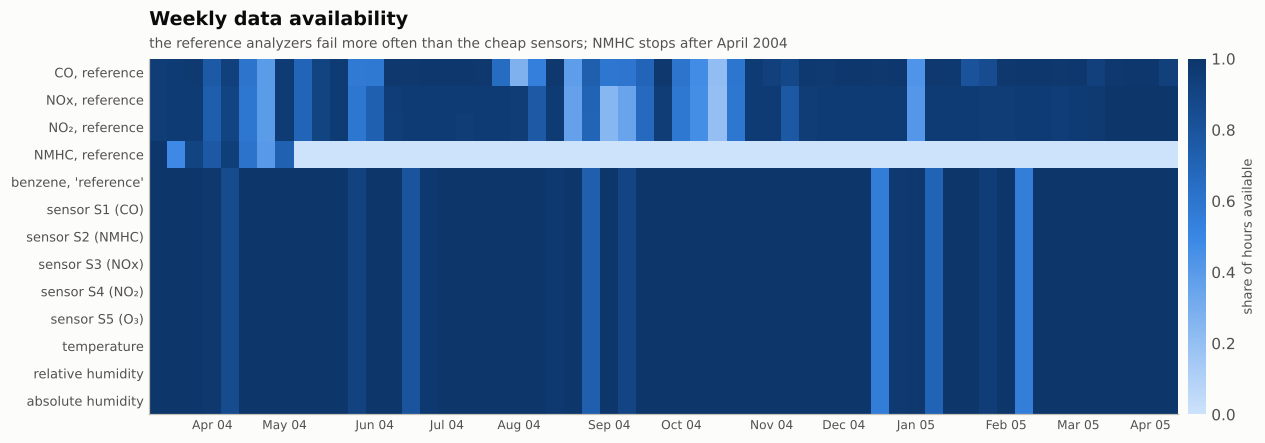

In [6]:
avail = u.notna().resample("W").mean().T
order = ["co_gt", "nox_gt", "no2_gt", "nmhc_gt", "c6h6_gt"] + SENSORS + METEO
names = {"co_gt": "CO, reference", "nox_gt": "NOx, reference", "no2_gt": "NO₂, reference",
         "nmhc_gt": "NMHC, reference", "c6h6_gt": "benzene, 'reference'", "s1_co": "sensor S1 (CO)",
         "s2_nmhc": "sensor S2 (NMHC)", "s3_nox": "sensor S3 (NOx)", "s4_no2": "sensor S4 (NO₂)",
         "s5_o3": "sensor S5 (O₃)", "t": "temperature", "rh": "relative humidity", "ah": "absolute humidity"}
fig, ax = plt.subplots(figsize=(12.5, 4.2))
im = ax.imshow(avail.loc[order].to_numpy(), aspect="auto", cmap=viz.BLUE_CMAP, vmin=0, vmax=1, interpolation="none")
ax.set_yticks(range(len(order)), [names[o] for o in order], fontsize=8.5)
ticks = [i for i, t in enumerate(avail.columns) if t.day <= 7]
ax.set_xticks(ticks, [avail.columns[i].strftime("%b %y") for i in ticks], fontsize=8)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01)
cb.set_label("share of hours available", fontsize=8.5)
cb.outline.set_visible(False)
viz.title(ax, "Weekly data availability", "the reference analyzers fail more often than the cheap sensors; "
          "NMHC stops after April 2004")
viz.save(fig, "02_availability")
plt.show()

## 3 · An hourly AQI for the city

The reference analyzers measure CO and NO2 (no particles, no ozone), so the index is
partial and traffic-driven:

* **EPA AQI**: NO2 1-hour (converted to ppb) and CO 8-hour rolling mean (converted to
  ppm, at least 6 valid hours in the window);
* **CAQI** (Citeair II, the European common index for city websites), hourly grid:
  NO2 hourly and CO 8-hour, in ug/m3.

In [7]:
aq = pd.DataFrame(index=u.index)
aq["no2_ppb"] = ix.ugm3_to_ppb(u.no2_gt, "no2")
aq["co_8h"] = u.co_gt.rolling(8, min_periods=6).mean()
aq["epa_no2"] = ix.epa_subindex(aq.no2_ppb, "no2")
aq["epa_co"] = ix.epa_subindex(ix.ugm3_to_ppb(aq.co_8h, "co"), "co")
aq["caqi_no2"] = ix.caqi_subindex(u.no2_gt, "no2")
aq["caqi_co"] = ix.caqi_subindex(aq.co_8h * 1000, "co_8h")
aq["epa_aqi"] = aq[["epa_no2", "epa_co"]].max(axis=1, skipna=False)
aq["caqi"] = aq[["caqi_no2", "caqi_co"]].max(axis=1, skipna=False)
aq["caqi_level"] = ix.caqi_level(aq.caqi)
print("dominant pollutant (CAQI):", (aq.caqi_no2 >= aq.caqi_co)[aq.caqi.notna()].mean().round(3), "share NO2")
lv = pd.Series(aq.caqi_level[aq.caqi.notna()]).value_counts(normalize=True).sort_index() * 100
display(pd.DataFrame({"CAQI level": [ix.CAQI_LEVELS[i] for i in lv.index], "% of hours": lv.round(1).to_numpy()}))
display(pd.Series(ix.epa_category_name(aq.epa_aqi.dropna(), short=True)).value_counts(normalize=True).mul(100).round(1)
        .rename("% of hours, EPA AQI"))

dominant pollutant (CAQI): 0.998 share NO2


,CAQI level,% of hours
0,Very low,7.8
1,Low,35.1
2,Medium,51.9
3,High,5.3


Moderate    49.1
Good        43.6
USG          7.2
Name: % of hours, EPA AQI, dtype: float64

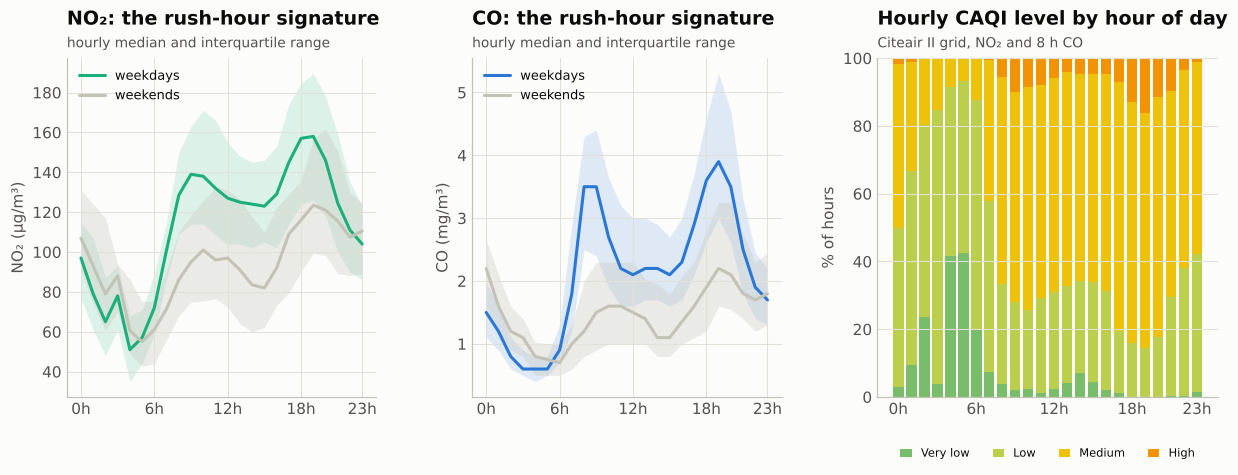

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0), gridspec_kw={"wspace": 0.3, "width_ratios": [1, 1, 1.1]})
for ax, (col, lab, color) in zip(axes[:2], [("no2_gt", "NO₂ (µg/m³)", viz.POLLUTANT_COLORS["no2"]),
                                             ("co_gt", "CO (mg/m³)", viz.POLLUTANT_COLORS["pm25"])]):
    s = u[col]
    for k, (name, mask) in enumerate([("weekdays", s.index.dayofweek < 5), ("weekends", s.index.dayofweek >= 5)]):
        g = s[mask].groupby(s[mask].index.hour)
        c = color if k == 0 else viz.CONTEXT
        ax.fill_between(range(24), g.quantile(0.25), g.quantile(0.75), color=c, alpha=0.14 if k == 0 else 0.3, lw=0)
        ax.plot(range(24), g.median(), color=c, lw=2, label=name)
    ax.set_xticks([0, 6, 12, 18, 23], ["0h", "6h", "12h", "18h", "23h"])
    ax.set_ylabel(lab)
    viz.title(ax, lab.split(" (")[0] + ": the rush-hour signature", "hourly median and interquartile range")
    ax.legend(loc="upper left", fontsize=8.5)
ax = axes[2]
lvl = pd.crosstab(aq.index.hour, aq.caqi_level.where(aq.caqi.notna()), normalize="index") * 100
lvl = lvl.drop(columns=[-1], errors="ignore")
bottom = np.zeros(24)
for k in sorted(lvl.columns):
    ax.bar(range(24), lvl[k], bottom=bottom, width=0.82, color=ix.CAQI_COLORS[int(k)], label=ix.CAQI_LEVELS[int(k)],
           lw=0)
    bottom += lvl[k].to_numpy()
ax.set_xticks([0, 6, 12, 18, 23], ["0h", "6h", "12h", "18h", "23h"])
ax.set_ylim(0, 100)
ax.set_ylabel("% of hours")
viz.title(ax, "Hourly CAQI level by hour of day", "Citeair II grid, NO₂ and 8 h CO")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=5, fontsize=7.5, handlelength=1)
ax.grid(axis="x", visible=False)
viz.save(fig, "02_hourly_aqi")
plt.show()

## 4 · Virtual reference analyzers

A MOx sensor does not measure a concentration: its resistance responds to several gases
at once and also to temperature and humidity, and it drifts as it ages. Calibration maps
the five sensor signals plus T, RH and AH to the reference concentration.

**Protocols.** The co-location period is the first 4 weeks. Then:

* *static*: calibrate once, never again (what a citizen sensor typically does);
* *quarterly*: recalibrate every 13 weeks on the 2 most recent weeks of reference data;
* *monthly*: every 4 weeks, on the 4 most recent weeks;
* *weekly*: every week, on the 4 most recent weeks (an upper bound).

**Models.** Linear regression on log-transformed signals (the textbook calibration) and
LightGBM. Inputs also include the hour of day and the last-3-hour mean of each sensor.

In [9]:
TARGETS = ["co_gt", "no2_gt", "nox_gt"]


def sensor_features(df: pd.DataFrame) -> pd.DataFrame:
    X = np.log(df[SENSORS]).add_prefix("log_")
    X = X.join(df[METEO])
    for s_ in SENSORS:
        X[f"log_{s_}_r3"] = np.log(df[s_]).rolling(3, min_periods=1).mean()
    X["hour_sin"] = np.sin(2 * np.pi * df.index.hour / 24)
    X["hour_cos"] = np.cos(2 * np.pi * df.index.hour / 24)
    return X


XS = sensor_features(u)
SCHEMES = {"static": (4, None), "quarterly": (2, 13), "monthly": (4, 4), "weekly": (4, 1)}
START = u.index[0].normalize() + pd.Timedelta(weeks=4)


def make_model(kind: str):
    if kind == "linear":
        return RidgeCV(alphas=np.logspace(-3, 2, 12))
    return lgb.LGBMRegressor(n_estimators=400, learning_rate=0.04, num_leaves=15, min_child_samples=20, subsample=0.8,
                             subsample_freq=1, colsample_bytree=0.8, verbose=-1, n_jobs=4)


def run_scheme(target: str, window_weeks: int, every_weeks, kind: str) -> pd.Series:
    y = u[target]
    ok = XS.notna().all(axis=1)
    preds = pd.Series(np.nan, index=u.index)
    t = START
    end = u.index[-1]
    model = None
    while t <= end:
        nxt = t + pd.Timedelta(weeks=every_weeks) if every_weeks else end + pd.Timedelta(hours=1)
        if model is None or every_weeks:
            win = (u.index >= t - pd.Timedelta(weeks=window_weeks)) & (u.index < t) & ok & y.notna()
            if win.sum() > 100:
                model = make_model(kind).fit(XS[win], y[win])
        seg = (u.index >= t) & (u.index < nxt) & ok
        if model is not None and seg.any():
            preds[seg] = model.predict(XS[seg])
        t = nxt
    return preds


vs_rows, vs_preds = [], {}
for target in TARGETS:
    for kind in ["linear", "lightgbm"]:
        for scheme, (w, e) in SCHEMES.items():
            p = run_scheme(target, w, e, kind)
            vs_preds[(target, kind, scheme)] = p
            m = u[target].notna() & p.notna() & (u.index >= START)
            vs_rows.append({"target": target, "model": kind, "scheme": scheme,
                            **fc.regression_scores(u[target][m], p[m])})
vs = pd.DataFrame(vs_rows)
display(vs.pivot_table(index=["target", "model"], columns="scheme", values="R2")[list(SCHEMES)].round(3))

scheme           static  quarterly  monthly  weekly
target model                                       
co_gt  lightgbm   0.879      0.753    0.832   0.858
       linear    -0.254      0.567    0.769   0.834
no2_gt lightgbm   0.339      0.662    0.716   0.792
       linear     0.235      0.253    0.663   0.799
nox_gt lightgbm   0.069      0.796    0.872   0.903
       linear    -0.502      0.728    0.794   0.887

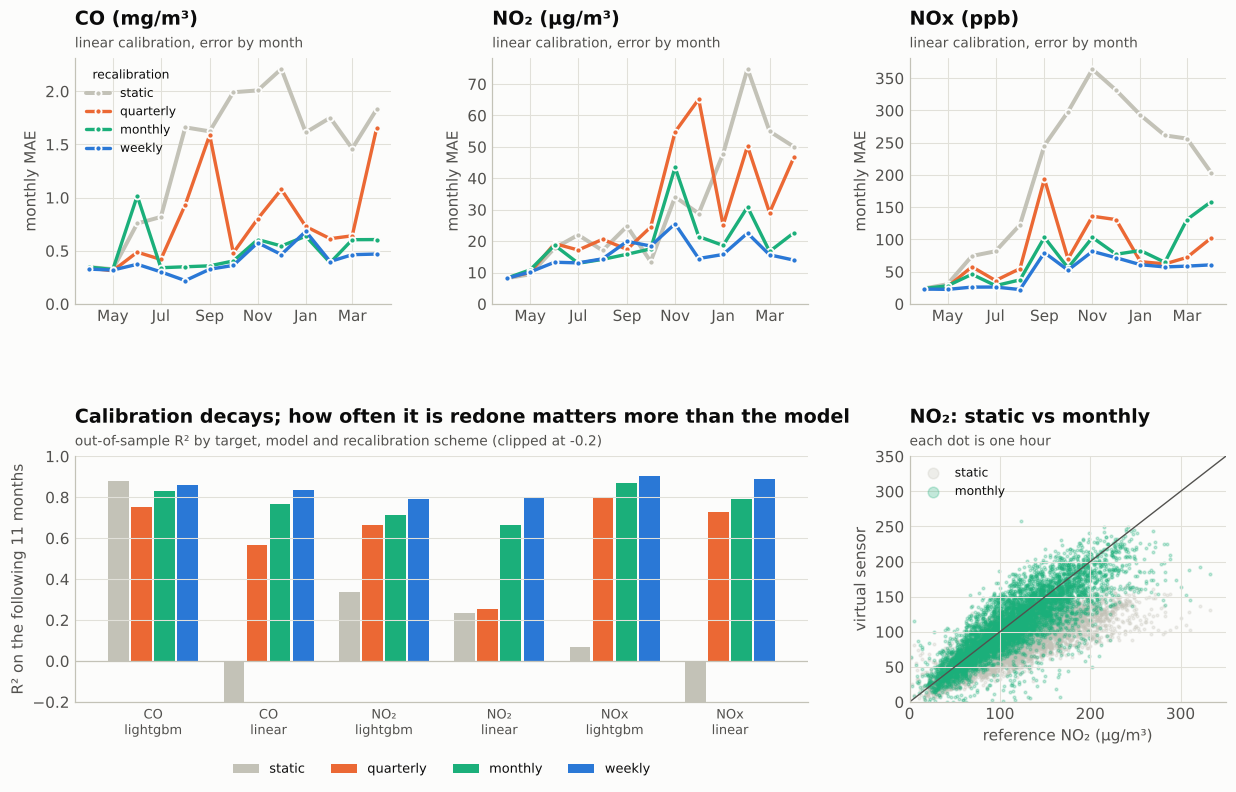

In [10]:
fig = plt.figure(figsize=(13.5, 7.6))
gs = fig.add_gridspec(2, 3, hspace=0.62, wspace=0.32)
for k, target in enumerate(TARGETS):
    ax = fig.add_subplot(gs[0, k])
    for j, scheme in enumerate(["static", "quarterly", "monthly", "weekly"]):
        p = vs_preds[(target, "linear", scheme)]
        err = (p - u[target]).abs()
        mon = err[u.index >= START].resample("MS").mean()
        color = [viz.CONTEXT, viz.SERIES[1], viz.SERIES[2], viz.SERIES[0]][j]
        ax.plot(mon.index, mon, color=color, lw=2.2 if scheme != "static" else 2.6, marker="o", ms=4,
                markeredgecolor=viz.SURFACE, markeredgewidth=1.2, label=scheme)
    ax.set_ylabel("monthly MAE")
    ax.set_ylim(bottom=0)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    viz.title(ax, LABELS[target], "linear calibration, error by month")
    if k == 0:
        ax.legend(loc="upper left", fontsize=8, title="recalibration", title_fontsize=8)
ax = fig.add_subplot(gs[1, 0:2])
piv = vs.pivot_table(index=["target", "model"], columns="scheme", values="R2")[list(SCHEMES)]
xlabels = [f"{LABELS[t].split(' (')[0]}\n{m}" for t, m in piv.index]
x = np.arange(len(piv))
for j, scheme in enumerate(SCHEMES):
    color = [viz.CONTEXT, viz.SERIES[1], viz.SERIES[2], viz.SERIES[0]][j]
    ax.bar(x + (j - 1.5) * 0.2, piv[scheme].clip(lower=-0.2), width=0.18, color=color, label=scheme)
ax.axhline(0, color=viz.AXIS, lw=0.8)
ax.set_xticks(x, xlabels, fontsize=8.5)
ax.set_ylabel("R² on the following 11 months")
ax.set_ylim(-0.2, 1)
viz.title(ax, "Calibration decays; how often it is redone matters more than the model",
          "out-of-sample R² by target, model and recalibration scheme (clipped at -0.2)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4, fontsize=8.5)
ax.grid(axis="x", visible=False)
ax = fig.add_subplot(gs[1, 2])
target = "no2_gt"
for scheme, color in [("static", viz.CONTEXT), ("monthly", viz.SERIES[2])]:
    p = vs_preds[(target, "linear", scheme)]
    m = u[target].notna() & p.notna() & (u.index >= START)
    ax.scatter(u[target][m], p[m], s=3, alpha=0.25, color=color, label=scheme, rasterized=True)
lim = [0, 350]
ax.plot(lim, lim, color=viz.INK_2, lw=0.9)
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_xlabel("reference NO₂ (µg/m³)")
ax.set_ylabel("virtual sensor")
viz.title(ax, "NO₂: static vs monthly", "each dot is one hour")
ax.legend(loc="upper left", markerscale=4, fontsize=8)
viz.save(fig, "02_virtual_sensing")
plt.show()

**Can a cheap sensor tell you your AQI?** With monthly recalibration, the CAQI computed
from the virtual NO2 and CO, against the CAQI from the reference analyzers:

exact level: 74.8%, within one level: 98.9%


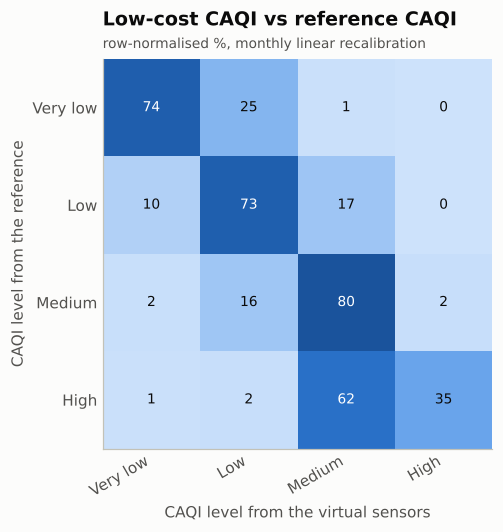

In [11]:
best = {t_: vs_preds[(t_, "linear", "monthly")] for t_ in ["co_gt", "no2_gt"]}
virt_caqi = np.fmax(ix.caqi_subindex(best["no2_gt"], "no2"),
                    ix.caqi_subindex(best["co_gt"].rolling(8, min_periods=6).mean() * 1000, "co_8h"))
m = aq.caqi.notna() & ~np.isnan(virt_caqi) & (u.index >= START)
ref_lvl, virt_lvl = ix.caqi_level(aq.caqi[m]), ix.caqi_level(virt_caqi[m])
conf = pd.crosstab(pd.Series(ref_lvl, name="reference"), pd.Series(virt_lvl, name="virtual"), normalize="index") * 100
conf.index = [ix.CAQI_LEVELS[i] for i in conf.index]
conf.columns = [ix.CAQI_LEVELS[i] for i in conf.columns]
lc_exact, lc_one = np.mean(ref_lvl == virt_lvl), np.mean(np.abs(ref_lvl - virt_lvl) <= 1)
print(f"exact level: {lc_exact:.1%}, within one level: {lc_one:.1%}")

fig, ax = plt.subplots(figsize=(5.8, 4.6))
im = ax.imshow(conf.to_numpy(), cmap=viz.BLUE_CMAP, vmin=0, vmax=100)
for i in range(conf.shape[0]):
    for j in range(conf.shape[1]):
        v = conf.iloc[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9, color="white" if v > 55 else viz.INK)
ax.set_xticks(range(conf.shape[1]), conf.columns, rotation=30, ha="right")
ax.set_yticks(range(conf.shape[0]), conf.index)
ax.set_xlabel("CAQI level from the virtual sensors")
ax.set_ylabel("CAQI level from the reference")
ax.grid(False)
viz.title(ax, "Low-cost CAQI vs reference CAQI", "row-normalised %, monthly linear recalibration")
viz.save(fig, "02_lowcost_caqi")
plt.show()

## 5 · Filling the gaps of the reference analyzers

The reference NO2 analyzer was down for a quarter of the hours of some months. Five ways
to fill a gap are compared by **masking known values**: 300 random blocks of 6 to 48
hours are hidden, refilled, and scored against the truth. The v1 method (one constant
for the whole table) is included for reference.

target,co_gt,no2_gt,nox_gt
method,,,
column mean,1.13,40.30,163.09
hour-of-week profile,0.79,32.41,143.16
linear interpolation,1.23,40.75,150.25
v1: single constant,454.99,342.54,264.49
virtual sensor (monthly recal.),0.55,21.91,79.52


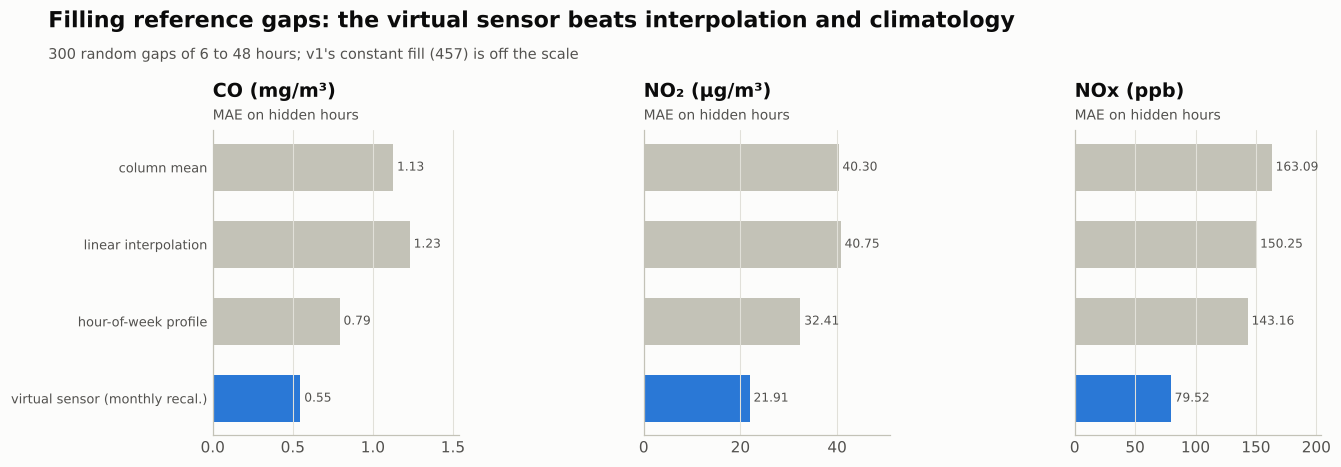

In [12]:
def gap_fill_benchmark(target: str, n_blocks: int = 300):
    y = u[target]
    hidden = pd.Series(False, index=u.index)
    starts_ = RNG.choice(np.arange(24 * 30, len(u) - 48), n_blocks, replace=False)
    for s_ in starts_:
        hidden.iloc[s_:s_ + RNG.integers(6, 49)] = True
    hidden &= y.notna()
    y_obs = y.mask(hidden)
    how = y_obs.groupby([y_obs.index.dayofweek, y_obs.index.hour]).transform("mean")
    vs_pred = vs_preds[(target, "linear", "monthly")]
    methods = {
        "v1: single constant": pd.Series(fill_value, index=u.index),
        "column mean": pd.Series(y_obs.mean(), index=u.index),
        "linear interpolation": y_obs.interpolate(limit_direction="both"),
        "hour-of-week profile": how,
        "virtual sensor (monthly recal.)": vs_pred.fillna(how),
    }
    return {name: fc.regression_scores(y[hidden], est[hidden]) for name, est in methods.items()}, int(hidden.sum())


gap_rows = []
for target in TARGETS:
    res, n_hidden = gap_fill_benchmark(target)
    for name, sc in res.items():
        gap_rows.append({"target": target, "method": name, "MAE": sc["MAE"], "R2": sc["R2"], "hidden hours": n_hidden})
gaps = pd.DataFrame(gap_rows)
display(gaps.pivot_table(index="method", columns="target", values="MAE").round(2))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"wspace": 0.75})
methods = gaps.method.unique()[1:]  # the v1 constant is off the scale; reported in the table
for ax, target in zip(axes, TARGETS):
    g = gaps[(gaps.target == target) & gaps.method.isin(methods)].set_index("method").loc[methods]
    colors = [viz.CONTEXT] * (len(g) - 1) + [viz.SERIES[0]]
    ax.barh(range(len(g)), g.MAE, height=0.6, color=colors)
    for i_, v_ in enumerate(g.MAE):
        ax.text(v_, i_, f" {v_:.2f}", va="center", fontsize=8, color=viz.INK_2)
    ax.set_yticks(range(len(g)), g.index if target == TARGETS[0] else [""] * len(g), fontsize=8.5)
    ax.invert_yaxis()
    ax.set_xlim(0, g.MAE.max() * 1.25)
    ax.grid(axis="y", visible=False)
    viz.title(ax, LABELS[target], "MAE on hidden hours")
viz.fig_title(fig, "Filling reference gaps: the virtual sensor beats interpolation and climatology",
              "300 random gaps of 6 to 48 hours; v1's constant fill (457) is off the scale")
viz.save(fig, "02_gap_filling")
plt.show()

## 6 · Forecasting the hourly CAQI, 1 to 24 hours ahead

**Target:** the hourly CAQI from the reference analyzers. **Features** at issue hour
*t*: CAQI, NO2 and CO lags (0 to 24 h) and rolling statistics (3 h to 1 week), the cheap
sensors (available even when the reference is down) and the meteorology at *t*, and the
calendar of the target hour. **Model:** quantile LightGBM with conformal calibration
(80% interval). **Protocol:** expanding window, monthly refits; test months November
2004 to April 2005. **Baselines:** persistence, same hour yesterday, hour-of-week
climatology.

In [13]:
caqi = aq.caqi.rename("caqi")
past = pd.concat([features.lag_features(u.no2_gt, [0, 1, 2, 3, 6, 12, 24], "no2"),
                  features.lag_features(u.co_gt, [0, 1, 2, 3, 24], "co"),
                  np.log(u[SENSORS]).rename(columns=lambda c: f"log_{c}"),
                  np.log(u[SENSORS]).rolling(6, min_periods=1).mean().rename(columns=lambda c: f"log_{c}_r6"),
                  u[METEO]], axis=1)
H = [1, 3, 6, 12, 24]
FOLDS = [(m_, m_ + pd.offsets.MonthEnd(1) + pd.Timedelta(hours=23)) for m_ in pd.date_range("2004-11-01", "2005-04-01",
                                                                                            freq="MS")]
f_rows, f_store = [], {}
for h in H:
    X, t = features.make_direct_dataset(caqi, h, lags=[0, 1, 2, 3, 6, 12, 24], windows=[3, 6, 24, 168],
                                        exog_past=past, hourly=True)
    p = fc.walk_forward(X, t, FOLDS, lambda: fc.QuantileBooster(alpha=0.2, params={"n_estimators": 350}),
                        min_train=2000)
    p["persistence"] = caqi.shift(h).reindex(p.index).to_numpy()
    p["yesterday"] = fc.seasonal_naive(caqi, h, 24).reindex(p.index).to_numpy()
    p["climatology"] = np.concatenate([fc.climatology(caqi, pd.Timestamp(f) - pd.Timedelta(hours=1), key="how")
                                       .reindex(p.index[p.fold == f]).to_numpy() for f in p.fold.unique()])
    f_store[h] = p
    ok_ = p.y.notna()
    row = {"h": h}
    for c in ["median", "persistence", "yesterday", "climatology"]:
        row[f"MAE {c}"] = fc.regression_scores(p.y[ok_], p[c][ok_])["MAE"]
    row["R2"] = fc.regression_scores(p.y, p["median"])["R2"]
    row["coverage 80%"] = fc.interval_scores(p.y, p.lo, p.hi, 0.2)["coverage"]
    row["coverage raw"] = fc.interval_scores(p.y, p.lo_raw, p.hi_raw, 0.2)["coverage"]
    row["level accuracy"] = np.mean(ix.caqi_level(p.y[ok_]) == ix.caqi_level(p["median"][ok_]))
    f_rows.append(row)
fscores = pd.DataFrame(f_rows).set_index("h")
display(fscores.round(3))

,MAE median,MAE persistence,MAE yesterday,MAE climatology,R2,coverage 80%,coverage raw,level accuracy
h,,,,,,,,
1,4.126,4.807,9.073,12.258,0.861,0.799,0.692,0.833
3,6.634,10.736,9.073,12.258,0.670,0.808,0.644,0.741
6,7.298,14.621,9.073,12.258,0.616,0.827,0.634,0.711
12,7.427,16.155,9.073,12.258,0.597,0.821,0.635,0.715
24,7.758,9.073,9.073,12.258,0.557,0.810,0.614,0.703


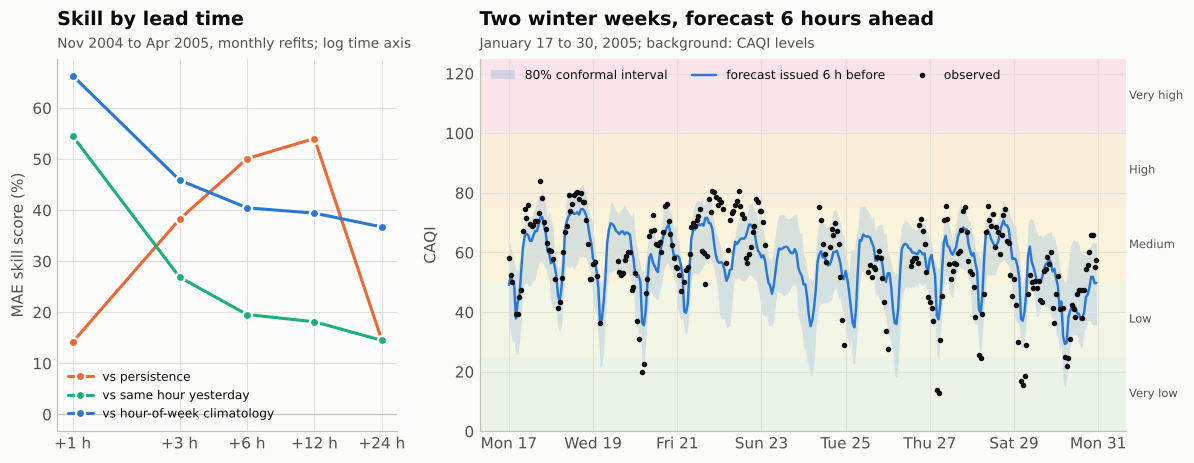

In [14]:
fig = plt.figure(figsize=(13.5, 4.4))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1.9, 0.0001], wspace=0.25)
ax = fig.add_subplot(gs[0])
for c, color, lab in [("persistence", viz.SERIES[1], "vs persistence"), ("yesterday", viz.SERIES[2],
                                                                           "vs same hour yesterday"),
                      ("climatology", viz.SERIES[0], "vs hour-of-week climatology")]:
    ax.plot(H, 100 * (1 - fscores["MAE median"] / fscores[f"MAE {c}"]), color=color, marker="o", ms=6,
            markeredgecolor=viz.SURFACE, markeredgewidth=1.5, label=lab)
ax.axhline(0, color=viz.AXIS, lw=0.8)
ax.set_xscale("log")
ax.set_xticks(H, [f"+{h} h" for h in H])
ax.minorticks_off()
ax.set_ylabel("MAE skill score (%)")
viz.title(ax, "Skill by lead time", "Nov 2004 to Apr 2005, monthly refits; log time axis")
ax.legend(loc="lower left", fontsize=8)
ax = fig.add_subplot(gs[1])
p = f_store[6]
seg = p.loc["2005-01-17":"2005-01-30"]
ax.fill_between(seg.index, seg.lo, seg.hi, color=viz.SERIES[0], alpha=0.16, lw=0, label="80% conformal interval")
ax.plot(seg.index, seg["median"], color=viz.SERIES[0], lw=1.6, label="forecast issued 6 h before")
ax.plot(seg.index, seg.y, color=viz.INK, lw=0, marker="o", ms=2.6, label="observed")
for k, (lo_, hi_) in enumerate(zip((0, 25, 50, 75, 100), (25, 50, 75, 100, 200))):
    ax.axhspan(lo_, hi_, color=ix.CAQI_COLORS[k], alpha=0.12, lw=0, zorder=0)
    ax.text(1.005, (lo_ + min(hi_, 125)) / 2, ix.CAQI_LEVELS[k], transform=ax.get_yaxis_transform(), fontsize=7.5,
            color=viz.INK_2, va="center")
ax.set_ylim(0, 125)
ax.set_ylabel("CAQI")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d"))
viz.title(ax, "Two winter weeks, forecast 6 hours ahead", "January 17 to 30, 2005; background: CAQI levels")
ax.legend(loc="upper left", ncol=3, fontsize=8)
viz.save(fig, "02_forecast")
plt.show()

## 7 · Why the sensors need recalibrating: humidity and temperature

Exact TreeSHAP contributions of a LightGBM NO2 calibration trained on the first month.
A MOx sensor's baseline resistance moves with absolute humidity and temperature, so the
calibration must "subtract" the weather: when the season changes, the static model is
applied to weather it never saw.

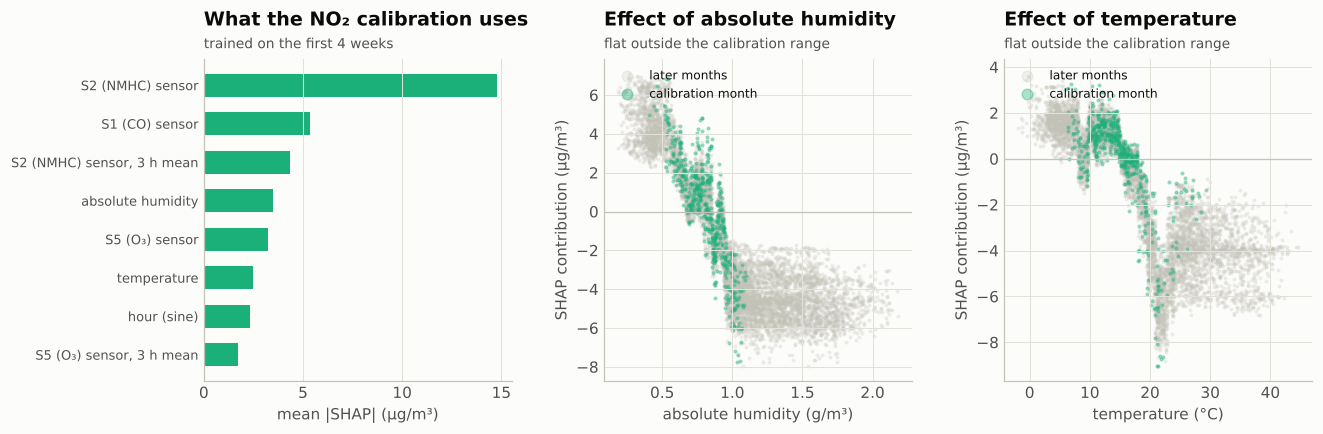

In [15]:
d_ = XS.join(u.no2_gt).dropna()
first = d_[d_.index < START]
booster = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.04, num_leaves=15, verbose=-1).fit(
    first.drop(columns="no2_gt"), first.no2_gt)
sv = pd.DataFrame(booster.booster_.predict(d_.drop(columns="no2_gt"), pred_contrib=True)[:, :-1],
                  columns=XS.columns, index=d_.index)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"wspace": 0.3})
ax = axes[0]
imp = sv.abs().mean().sort_values().tail(8)
pretty = {"log_s4_no2": "S4 (NO₂) sensor", "log_s2_nmhc": "S2 (NMHC) sensor", "log_s3_nox": "S3 (NOx) sensor",
          "log_s1_co": "S1 (CO) sensor", "log_s5_o3": "S5 (O₃) sensor", "t": "temperature",
          "rh": "relative humidity", "ah": "absolute humidity", "hour_sin": "hour (sine)", "hour_cos": "hour (cosine)"}
ax.barh(range(len(imp)), imp, color=viz.SERIES[2], height=0.6)
ax.set_yticks(range(len(imp)), [pretty[c] if c in pretty else pretty.get(c[:-3], c) + ", 3 h mean"
                                for c in imp.index], fontsize=8.5)
ax.set_xlabel("mean |SHAP| (µg/m³)")
ax.grid(axis="y", visible=False)
viz.title(ax, "What the NO₂ calibration uses", "trained on the first 4 weeks")
for ax, var, lab in [(axes[1], "ah", "absolute humidity (g/m³)"), (axes[2], "t", "temperature (°C)")]:
    inside = d_.index < START
    ax.scatter(d_[var][~inside], sv[var][~inside], s=3, alpha=0.2, color=viz.CONTEXT, label="later months",
               rasterized=True)
    ax.scatter(d_[var][inside], sv[var][inside], s=3, alpha=0.35, color=viz.SERIES[2], label="calibration month",
               rasterized=True)
    ax.axhline(0, color=viz.AXIS, lw=0.8)
    ax.set_xlabel(lab)
    ax.set_ylabel("SHAP contribution (µg/m³)")
    viz.title(ax, f"Effect of {lab.split(' (')[0]}", "flat outside the calibration range")
    ax.legend(loc="upper left", markerscale=4, fontsize=8)
viz.save(fig, "02_shap_meteo")
plt.show()

Trees cannot extrapolate: outside the humidity and temperature range of the
co-location month, the learned correction freezes at its edge value. When the seasons
change, a static calibration is applied to weather it never saw, one reason why the NO2
and NOx calibrations collapse within weeks unless they are redone.

## 8 · Take-aways

* v1's numbers were driven by preprocessing artefacts (-200 codes kept as values, a 457
  fill value) and by a random split of an hourly time series.
* The benzene "reference" of the UCI dataset is a polynomial of one sensor: it must not
  be used to benchmark models.
* Cheap MOx sensors make good **virtual analyzers for NO2 and NOx only if they are
  recalibrated**: a one-off calibration loses most of its skill within a few months,
  monthly co-location recovers most of it. The CO sensor is the exception: a nonlinear
  calibration from the first month stays accurate all year.
* The virtual sensors fill reference gaps with about half the error of interpolation or
  climatology, and the CAQI they produce matches the reference level 3 hours in 4 and is
  within one level almost always.
* The hourly CAQI forecast beats persistence, yesterday's value and the hour-of-week
  climatology at every lead time from 1 to 24 hours, and conformal calibration restores
  the nominal coverage of its intervals.

## 9 · Key results

Saved to `data/processed/results_02.json` for the report.

In [16]:
import json  # noqa: E402

piv = vs.pivot_table(index=["target", "model"], columns="scheme", values="R2")[list(SCHEMES)]
gp_ = gaps.pivot_table(index="method", columns="target", values="MAE")
res02 = {
    "v1_rf_mae": round(float(protocols.loc["v1 as published", "MAE"]), 1),
    "v1_rf_r2": round(float(protocols.loc["v1 as published", "R2"]), 3),
    "random_r2": round(float(protocols.loc["clean data, random split", "R2"]), 3),
    "chrono_r2": round(float(protocols.loc["clean data, chronological split", "R2"]), 3),
    "fill_value": round(float(fill_value), 1), "benzene_r2": round(float(bz_r2), 5),
    "lowcost_exact": round(100 * float(lc_exact), 0), "lowcost_one": round(100 * float(lc_one), 0),
    "vs_r2": {f"{t}|{m}": {k: round(float(v), 2) for k, v in row.items()} for (t, m), row in piv.iterrows()},
    "gap_mae": {m: {t: round(float(v), 2) for t, v in row.items()} for m, row in gp_.iterrows()},
    "forecast": {int(h): {"mae": round(float(row["MAE median"]), 2),
                          "skill_pers": round(100 * (1 - row["MAE median"] / row["MAE persistence"]), 0),
                          "skill_clim": round(100 * (1 - row["MAE median"] / row["MAE climatology"]), 0),
                          "cov": round(100 * float(row["coverage 80%"]), 0),
                          "cov_raw": round(100 * float(row["coverage raw"]), 0)} for h, row in fscores.iterrows()},
}
(data.DATA / "processed" / "results_02.json").write_text(json.dumps(res02, indent=1))
display(pd.Series({k: v for k, v in res02.items() if not isinstance(v, dict)}))

v1_rf_mae         22.50000
v1_rf_r2           0.64300
random_r2          0.92000
chrono_r2          0.88000
fill_value       457.10000
benzene_r2         0.99998
lowcost_exact     75.00000
lowcost_one       99.00000
dtype: float64